## Discovery flow

```{mermaid}
flowchart TD
 A[Five corrected development imputations; all-cause mortality] --> B[04: new tuning and all-imputation selection]
 B --> C[Reuse fitted networks and each training-fold baseline]
 C --> D[First imputation: 500 validation participants per fold]
 D --> E[Explain risk separately at 3, 6, 12, 36, 60 and 96 months]
 E --> F[Observed horizon ranks and original numerical thresholds]
 F --> G[Expand selected categorical families in Cox]
 E --> H[Risk-scale residual screening and functional-form plots]
 G --> I[12: sequential sensitivity comparisons]
 H --> I
 J[Historical log-hazard matrices] --> K[Reference reproduction only; no temporal stability claim]
```

Mortality includes every death, including after readmission. Readmission is unchanged. Each target is the fitted model's net risk **1-S(t)**, not a competing-risk CIF. The score, training baseline, background sample and validation participants remain fixed within each fold; the horizon-specific probability map is differentiated separately. The baseline is not refitted on validation or held-out participants.

Expected gradients provide a **SHAP approximation**, not DeepExplainer on log partial hazard. A shared-gradient calculation avoids repeating the neural derivative six times and is checked against the installed `shap.GradientExplainer` for every fold/outcome. It uses one CPU thread, 2,048 Monte Carlo paths per person, the original 100 training background rows and 2,500 validation participants. No network is refitted. Numerical reconstruction error and a double-sample check are shown below. A mean reconstruction error exceeding 10% of the mean absolute risk contrast stops selection; this is a numerical safeguard, not the study's model-selection rule.

Full-development imputation precedes internal CV, as agreed; internal preprocessing is not completely independent. Explanations use imputation 1 and do not measure variability across imputations. With a proportional-hazards network, differing risk contributions across horizons do not imply time-varying coefficients. These are dependent descriptive summaries, not temporal validation.

Method: [SHAP expected-gradients documentation](https://shap.readthedocs.io/en/stable/generated/shap.GradientExplainer.html) and [official PyTorch implementation](https://github.com/shap/shap/blob/master/shap/explainers/_gradient.py).

In [1]:
#| label: ds-shap-config-and-verified-helpers
#| message: false
import time
t0 = time.perf_counter()
# Reuse only setup, data and model helpers from 04; never trigger its search stages here.
import json
from pathlib import Path
root=Path.cwd().resolve()
while not (root/'config.yml').is_file():
    if root.parent==root:raise FileNotFoundError('config.yml not found')
    root=root.parent
import yaml
config=yaml.safe_load((root/'config.yml').read_text(encoding='utf-8'))
p=Path(config['sources']['deepsurv_tuning_notebook']);p=p if p.is_absolute() else root/p
upstream=json.loads(p.read_text(encoding='utf-8'))
for label in ['ds-config-and-environment','ds-development-endpoint-and-encoding','ds-fit-and-score-functions']:
    matches=[''.join(c['source']) for c in upstream['cells'] if c['cell_type']=='code' and ''.join(c['source']).startswith(f'#| label: {label}\n')]
    assert len(matches)==1;exec(compile(matches[0],f'{p.name}:{label}','exec'),globals())
import shap
explanation_settings=config['deepsurv_explanations']
explanation_horizons=np.asarray(explanation_settings['horizons_months'],float)
explanation_device='cpu'
assert np.array_equal(explanation_horizons,[3,6,12,36,60,96]) and explanation_settings['method']=='expected_gradients_horizon_risk' and explanation_settings['nsamples']>=2048
import matplotlib.pyplot as plt
from scipy.stats import t as tdist,spearmanr
selected_path=artifact('DeepSurv_selected_configuration',analysis_signature)
assert selected_path.exists(),'Complete notebook 04 before running horizon-specific SHAP.'
selected=load(selected_path)
assert selected['selection']=='minimum_original_objective_across_five_imputations' and not selected['historical_choice_used_for_new_networks']
assert selected['data_signature']==data_signature and selected['features']==contract['features']
assert selected['endpoint']==settings['endpoint']=='first_readmission_and_all_cause_death'
records=selected['reassessment'];assert len(records)==25
explanation_code=json.loads((root/config['paths']['notebooks']/'05_DeepSurv2_mar26.ipynb').read_text(encoding='utf-8'))
code_hash=fingerprint([''.join(c['source']) for c in explanation_code['cells'] if c['cell_type']=='code'])
shap_signature=fingerprint({'code':code_hash,'selected_sha':sha(selected_path),'settings':{k:settings[k] for k in ['shap_background','shap_per_fold','shap_imputations']},'shap_version':importlib.metadata.version('shap'),'explanations':explanation_settings,'selection_rule':'ds63_thresholds_on_real_horizon_ranks_descriptive_percentiles'})
features=selected['features'];figure_dir=resolve_path(config['paths']['figures']);show_table(pd.DataFrame([selected['params']]),'Newly selected configuration actually used for horizon-specific SHAP')
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Notebook,Environment,Python,GPU,CPU threads,Available RAM GiB
04_DeepSurv_mar26.ipynb,surv-deephit,3.11.14,NVIDIA RTX A1000,1,66.360863


Elapsed: 0.060 minutes


Development,Readmissions,Previous neural death events,New all-cause neural death events,Additional deaths after readmission,Death follow-up times extended beyond readmission,Zero-time death events retained,Holdout rows used,Features
70521,15247,2444,3039,595,15247,160,0,55


Elapsed: 0.033 minutes
Elapsed: 0.000 minutes


lr,weight_decay,batch_size,dropout,nodes,epochs,patience
0.003134,0.000406,512,0.574062,"[128, 64]",72,13


Elapsed: 0.016 minutes


In [2]:
#| label: ds-shap-horizon-risk-functions
#| message: false
t0 = time.perf_counter()
# Explain the actual probability map; the baseline belongs to the training fold.
def baseline_at(base, requested):
    grid = base.index.to_numpy(dtype=float)
    values = base.to_numpy(dtype=float)
    assert len(grid) and np.isfinite(values).all() and (values >= 0).all() and (np.diff(grid) > 0).all() and (np.diff(values) >= -1e-12).all()
    pos = np.searchsorted(grid, requested, side='right') - 1
    return np.where(pos >= 0, values[np.maximum(pos, 0)], 0.)
class HorizonRisk(torch.nn.Module):
    def __init__(self, net, cumulative_baseline):
        super().__init__()
        self.net = net
        self.register_buffer('baseline', torch.as_tensor(cumulative_baseline, dtype=torch.float32))
    def forward(self, x):
        return -torch.expm1(-torch.exp(self.net(x)) * self.baseline)
def expected_gradients_risk(net, cumulative, background, evaluation, nsamples, random_seed):
    # Reuse one log-hazard gradient for all six probability maps; keep SHAP's exact random draws.
    rng = np.random.RandomState(random_seed)
    baseline = torch.as_tensor(cumulative, dtype=torch.float32, device=evaluation.device)
    values = np.empty((len(evaluation), evaluation.shape[1], len(cumulative)), dtype='float32')
    for j in range(len(evaluation)):
        draws = [(rng.choice(len(background)), rng.uniform()) for _ in range(nsamples)]
        ix = torch.tensor([d[0] for d in draws], device=evaluation.device)
        alpha = torch.tensor([d[1] for d in draws], dtype=torch.float32, device=evaluation.device)[:,None]
        complement = torch.tensor([1-d[1] for d in draws], dtype=torch.float32, device=evaluation.device)[:,None]
        sampled_background = background[ix]
        points = (alpha * evaluation[j] + complement * sampled_background).detach().requires_grad_(True)
        lp = net(points)
        gradient = torch.autograd.grad(lp.sum(), points)[0]
        cumulative_hazard = torch.exp(lp.detach()) * baseline
        link_gradient = cumulative_hazard * torch.exp(-cumulative_hazard)
        risk_gradient = (gradient[:,:,None] * link_gradient[:,None,:]).double()
        delta = (evaluation[j] - sampled_background).double()
        values[j] = (risk_gradient * delta[:,:,None]).mean(dim=0).float().cpu().numpy()
    return values
def explain_horizon_risk(net, base, background, evaluation, requested, nsamples, random_seed):
    cumulative = baseline_at(base, requested)
    model = HorizonRisk(net, cumulative).to(evaluation.device).eval()
    with torch.no_grad():
        predictions = model(evaluation).cpu().numpy()
        expected = model(background).mean(dim=0).cpu().numpy()
        lp = net(evaluation).cpu().numpy()
    reference = -np.expm1(-np.exp(lp.astype(float)) * cumulative)
    error = float(np.max(np.abs(predictions - reference)))
    assert error < 2e-7 and np.isfinite(predictions).all() and ((predictions >= 0) & (predictions <= 1)).all(), error
    assert (np.diff(predictions, axis=1) >= -1e-7).all()
    values = expected_gradients_risk(net, cumulative, background, evaluation, int(nsamples), int(random_seed))
    assert values.shape == (len(evaluation), evaluation.shape[1], len(requested)) and np.isfinite(values).all()
    residual = values.sum(axis=1) + expected - predictions
    diagnostics = []
    for j, horizon in enumerate(requested):
        absolute = np.abs(residual[:, j])
        signal = float(np.mean(np.abs(predictions[:, j] - expected[j])))
        diagnostics.append({'Horizon':float(horizon), 'Baseline':float(cumulative[j]), 'Expected_risk':float(expected[j]), 'Mean_risk':float(predictions[:, j].mean()), 'Probability_check_max_error':error, 'Mean_absolute_reconstruction_error':float(absolute.mean()), 'P95_absolute_reconstruction_error':float(np.quantile(absolute, .95)), 'Max_absolute_reconstruction_error':float(absolute.max()), 'Reconstruction_error_over_mean_signal':float(absolute.mean() / signal) if signal > 0 else 0., 'Training_baseline_extends_to_horizon':bool(horizon <= base.index.max()), 'Monte_Carlo_samples':int(nsamples)})
    return {'values':values.astype('float32'), 'base_values':expected, 'predictions':predictions, 'diagnostics':diagnostics}
# Exercise the pre-event edge and a two-output linear attribution control.
assert np.array_equal(baseline_at(pd.Series([.2,.4], index=[2.,4.]), [0,2,3,4,6]), [0,.2,.2,.4,.4])
toy = torch.nn.Linear(2,2,bias=False).to(explanation_device)
with torch.no_grad(): toy.weight.copy_(torch.tensor([[1.,2.],[3.,-1.]], device=explanation_device))
toy_background = torch.zeros((4,2), device=explanation_device)
toy_x = torch.tensor([[1.,2.],[-1.,1.]], device=explanation_device)
toy_values = np.asarray(shap.GradientExplainer(toy,toy_background).shap_values(toy_x,nsamples=32,rseed=seed))
assert np.allclose(toy_values,toy_x.cpu().numpy()[:,:,None] * toy.weight.detach().cpu().numpy().T,atol=1e-6)
del toy,toy_background,toy_x,toy_values
print('Probability-map and multi-output attribution controls passed. Expected gradients approximate SHAP; reconstruction residuals are reported, not rescaled away.')
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


Probability-map and multi-output attribution controls passed. Expected gradients approximate SHAP; reconstruction residuals are reported, not rescaled away.
Elapsed: 0.000 minutes


In [3]:
#| label: ds-shap-native-performance
#| message: false
t0 = time.perf_counter()
# Display the current native-network results as discovery checks, not as the Cox eTable 9.
rows=[]
for record in records:
    for cause,result in record['outcomes'].items():
        for j,h in enumerate(horizons):rows.append({'Outcome':cause,'Horizon':h,'Imputation':record['Imp'],'Fold':record['Fold'],'Uno_C':result['C'][j],'IBS_3_to_60':result['IBS'],'Epochs':result['epochs']})
native=pd.DataFrame(rows)
show_table(native.groupby(['Outcome','Horizon'],as_index=False).agg(Uno_C=('Uno_C','mean'),IBS_3_to_60=('IBS_3_to_60','mean'),Epochs_min=('Epochs','min'),Epochs_max=('Epochs','max')),'Native DeepSurv: averaged fold metrics; IBS integrates 3 to 60 months')
assert native.Uno_C.notna().all() and native.IBS_3_to_60.notna().all()
print('No new neural fit was needed: all 25 pairs are reused from the selected configuration in 04.')
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Horizon,Uno_C,IBS_3_to_60,Epochs_min,Epochs_max
Death,3.0,0.786785,0.022954,16,43
Death,6.0,0.771522,0.022954,16,43
Death,12.0,0.761496,0.022954,16,43
Death,36.0,0.765660,0.022954,16,43
Death,60.0,0.765716,0.022954,16,43
Readmission,3.0,0.659222,0.137134,22,66
Readmission,6.0,0.648296,0.137134,22,66
Readmission,12.0,0.637433,0.137134,22,66
Readmission,36.0,0.622909,0.137134,22,66
Readmission,60.0,0.617963,0.137134,22,66


No new neural fit was needed: all 25 pairs are reused from the selected configuration in 04.
Elapsed: 0.000 minutes


In [4]:
#| label: ds-shap-compute-2500-validation-participants
#| message: false
t0 = time.perf_counter()
# Reuse fitted fold networks; explain validation rows against training-only reference rows.
shap_path=artifact('DeepSurv_horizon_risk_SHAP',shap_signature)
if shap_path.exists():bundle=load(shap_path);written.append(shap_path)
else:
    pieces=[]
    for fold in range(5):
        record=next(r for r in records if r['Imp']==1 and r['Fold']==fold)
        fp=artifact(f'DeepSurv_horizon_risk_SHAP_fold{fold+1}',shap_signature)
        if fp.exists():piece=load(fp)
        else:
            assert psutil.virtual_memory().available/2**30>settings['reserve_memory_gib']+3
            batch=fold_data(1,fold);rng=np.random.RandomState(seed+fold)
            bg=rng.choice(len(batch['train']),settings['shap_background'],replace=False)
            chosen=rng.choice(len(batch['valid']),settings['shap_per_fold'],replace=False)
            original_indices=batch['valid_idx'][chosen]
            _,validation_raw=encode_fold(completed(1).iloc[batch['train_idx']],completed(1).iloc[batch['valid_idx']])
            piece={'ids':ids[original_indices],'positions':original_indices,'fold':fold,'X_raw':validation_raw.iloc[chosen].copy(),'X_scaled':batch['valid'][chosen],'values':{},'base_values':{},'predictions':{},'diagnostics':[],'method_controls':[],'precision_checks':[]}
            for cause in ['Death','Readmission']:
                model=make_model(selected['params'],len(features));model.net.load_state_dict(record['models'][cause]['state']);model.net.to(explanation_device).eval()
                background=torch.tensor(batch['train'][bg],dtype=torch.float32,device=explanation_device)
                evaluation=torch.tensor(batch['valid'][chosen],dtype=torch.float32,device=explanation_device)
                baseline=record['models'][cause]['cumulative_baseline']
                requested=explanation_horizons;random_seed=seed+fold
                # Anchor the faster chain-rule computation to the installed public SHAP API.
                direct_model=HorizonRisk(model.net,baseline_at(baseline,requested)).to(explanation_device).eval()
                official=np.asarray(shap.GradientExplainer(direct_model,background,batch_size=128).shap_values(evaluation[:4],nsamples=64,rseed=random_seed))
                fast=expected_gradients_risk(model.net,baseline_at(baseline,requested),background,evaluation[:4],64,random_seed)
                method_error=float(np.max(np.abs(official-fast)));assert method_error<2e-6,(cause,fold,method_error)
                started=time.perf_counter()
                result=explain_horizon_risk(model.net,baseline,background,evaluation,requested,explanation_settings['nsamples'],random_seed)
                for name in ['values','base_values','predictions']:piece[name][cause]=result[name]
                for row in result['diagnostics']:piece['diagnostics'].append({'Fold':fold+1,'Outcome':cause,**row})
                (resolve_path(config['paths']['docs'])/'05_horizon_numerical_checks.json').write_text(json.dumps({'shap_signature':shap_signature,'fold':fold+1,'outcome':cause,'diagnostics':result['diagnostics']},indent=2),encoding='utf-8')
                assert all(r['Reconstruction_error_over_mean_signal']<=.10 for r in result['diagnostics']),'Monte Carlo precision insufficient; inspect diagnostics and increase nsamples before selection.'
                refined=explain_horizon_risk(model.net,baseline,background,evaluation[:32],requested,2*explanation_settings['nsamples'],random_seed)
                for j,h in enumerate(requested):
                    a=result['values'][:32,:,j];b=refined['values'][:,:,j]
                    piece['precision_checks'].append({'Fold':fold+1,'Outcome':cause,'Horizon':float(h),'Participants':32,'Base_samples':explanation_settings['nsamples'],'Refined_samples':2*explanation_settings['nsamples'],'Mean_absolute_attribution_change':float(np.abs(a-b).mean()),'Importance_rank_correlation':float(spearmanr(np.abs(a).mean(axis=0),np.abs(b).mean(axis=0)).statistic)})
                piece['method_controls'].append({'Fold':fold+1,'Outcome':cause,'Official_SHAP_max_error':method_error,'Seconds':time.perf_counter()-started})
                del model,direct_model,background,evaluation,official,fast,refined,result;gc.collect();torch.cuda.empty_cache()
            save(piece,fp)
        pieces.append(piece);print(f'Horizon-specific risk explanations: fold {fold+1}/5 complete',flush=True)
        (resolve_path(config['paths']['docs'])/'05_horizon_progress.json').write_text(json.dumps({'completed_folds':fold+1,'total_folds':5,'shap_signature':shap_signature,'at':datetime.datetime.now().astimezone().isoformat()}),encoding='utf-8')
    bundle={'ids':np.concatenate([x['ids'] for x in pieces]),'positions':np.concatenate([x['positions'] for x in pieces]),'X_raw':pd.concat([x['X_raw'] for x in pieces],ignore_index=True),'X_scaled':np.concatenate([x['X_scaled'] for x in pieces]),'feature_names':features,'values':{c:np.concatenate([x['values'][c] for x in pieces]) for c in ['Death','Readmission']},'predictions':{c:np.concatenate([x['predictions'][c] for x in pieces]) for c in ['Death','Readmission']},'diagnostics':[r for x in pieces for r in x['diagnostics']],'method_controls':[r for x in pieces for r in x['method_controls']],'precision_checks':[r for x in pieces for r in x['precision_checks']],'fold_base_values':[{c:x['base_values'][c] for c in ['Death','Readmission']} for x in pieces],'selected_signature':analysis_signature,'shap_scale':'net_risk_1_minus_survival','explanation_method':explanation_settings['method'],'horizons':explanation_horizons,'sampling_imputation':1,'patients_per_fold':settings['shap_per_fold']}
    assert len(bundle['ids'])==len(np.unique(bundle['ids']))==2500
    save(bundle,shap_path)
assert len(bundle['ids'])==2500 and bundle['feature_names']==features and bundle['shap_scale']=='net_risk_1_minus_survival'
assert np.array_equal(bundle['horizons'],explanation_horizons)
for cause in ['Death','Readmission']:assert bundle['values'][cause].shape==(2500,len(features),6)
show_table(pd.DataFrame(bundle['method_controls']),'Executed control against SHAP GradientExplainer; no new neural fitting')
show_table(pd.DataFrame(bundle['diagnostics']),'Probability reconstruction and follow-up support by horizon; Monte Carlo residuals are not confidence intervals')
show_table(pd.DataFrame(bundle['precision_checks']),'Descriptive numerical check: twice the path samples on 32 participants per fold')
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


Horizon-specific risk explanations: fold 1/5 complete


Horizon-specific risk explanations: fold 2/5 complete


Horizon-specific risk explanations: fold 3/5 complete


Horizon-specific risk explanations: fold 4/5 complete


Horizon-specific risk explanations: fold 5/5 complete


Fold,Outcome,Official_SHAP_max_error,Seconds
1,Death,2.773671e-09,11.473063
1,Readmission,7.147158e-09,10.990657
2,Death,3.619017e-09,10.824398
2,Readmission,5.463453e-09,10.869581
3,Death,6.179991e-09,10.888227
3,Readmission,6.151547e-09,11.003605
4,Death,2.921070e-09,10.794275
4,Readmission,3.837221e-09,10.838932
5,Death,3.490005e-09,10.906430
5,Readmission,3.277269e-09,10.783817


Fold,Outcome,Horizon,Baseline,Expected_risk,Mean_risk,Probability_check_max_error,Mean_absolute_reconstruction_error,P95_absolute_reconstruction_error,Max_absolute_reconstruction_error,Reconstruction_error_over_mean_signal,Training_baseline_extends_to_horizon,Monte_Carlo_samples
1,Death,3.0,0.005694,0.004236,0.004920,2.686749e-08,0.000122,0.000308,0.000837,0.029465,True,2048
1,Death,6.0,0.008172,0.006065,0.007037,2.686749e-08,0.000174,0.000439,0.001194,0.029454,True,2048
1,Death,12.0,0.012862,0.009506,0.011006,2.686749e-08,0.000271,0.000683,0.001859,0.029433,True,2048
1,Death,36.0,0.035789,0.025912,0.029715,2.686749e-08,0.000721,0.001801,0.004906,0.029328,True,2048
1,Death,60.0,0.059505,0.042198,0.047953,2.686749e-08,0.001146,0.002872,0.007725,0.029249,True,2048
1,Death,96.0,0.097947,0.067231,0.075393,2.686749e-08,0.001763,0.004406,0.011647,0.029236,True,2048
1,Readmission,3.0,0.048129,0.044715,0.043721,4.242455e-08,0.000434,0.001039,0.001865,0.030663,True,2048
1,Readmission,6.0,0.081530,0.074317,0.072740,4.242455e-08,0.000708,0.001695,0.003033,0.030585,True,2048
1,Readmission,12.0,0.132837,0.117642,0.115317,4.242455e-08,0.001090,0.002619,0.004645,0.030485,True,2048
1,Readmission,36.0,0.248635,0.206699,0.203238,4.242455e-08,0.001799,0.004321,0.007584,0.030311,True,2048


Fold,Outcome,Horizon,Participants,Base_samples,Refined_samples,Mean_absolute_attribution_change,Importance_rank_correlation
1,Death,3.0,32,2048,4096,0.000010,0.999206
1,Death,6.0,32,2048,4096,0.000015,0.999206
1,Death,12.0,32,2048,4096,0.000023,0.999278
1,Death,36.0,32,2048,4096,0.000062,0.999351
1,Death,60.0,32,2048,4096,0.000099,0.998918
1,Death,96.0,32,2048,4096,0.000154,0.999567
1,Readmission,3.0,32,2048,4096,0.000050,0.999711
1,Readmission,6.0,32,2048,4096,0.000081,0.999639
1,Readmission,12.0,32,2048,4096,0.000125,0.999134
1,Readmission,36.0,32,2048,4096,0.000205,0.999495


Elapsed: 1.959 minutes


## Predictor rules and their limit

Each feature receives a separate mean absolute risk contribution and rank at each of the six horizons. The original numerical thresholds are retained: a top-15 rank in at least 75% of horizons (at least five of six); readmission also requires an observed 97.5th rank percentile at most 20, and mortality at least 10% of the largest mean absolute contribution. Treatment-setting signals supply strata and are omitted from the listing; selected categorical families are expanded in Cox.

The six horizons receive equal weight in mean absolute **probability** contributions. Because probabilities and their contributions can be larger at later horizons, equal weighting does not equalize contribution scales. The per-horizon table and rank heatmap make this visible. Rank minima, maxima and percentiles describe the six observed ranks; they are **not confidence intervals**. The frequency is descriptive consistency, not evidence of temporal stability. No bootstrap or independent replication is implied.

The old log-hazard calculation remains a separate numerical reference. Its duplicated matrices, degenerate rank bounds and 0/100 frequency are never supplied to the new Cox selection. Old and new contribution magnitudes have different units and are not subtracted. Changes to predictor inclusion are listed explicitly; primary XGBoost-informed b/e are unchanged.

In [5]:
#| label: ds-shap-ranking-and-historical-control
#| message: false
t0 = time.perf_counter()
# The old rule is tested only as a historical reference; new ranks use separate probability explanations.
def historical_rank_table(values,feature_names,cause):
    values=np.asarray(values,dtype='float32').astype(float);importance=np.abs(values).mean(axis=0)
    rank=pd.Series(importance).rank(method='min',ascending=False).to_numpy()
    z=pd.DataFrame({'outcome':cause,'feature':feature_names,'mean_abs_shap_risk':importance,'mean_abs_shap_log_hazard':importance,'mean_rank':rank,'rank_ci2p5':rank,'rank_ci97p5':rank,'horizon_count':6,'freq_in_top_15_pct':np.where(rank<=15,100.,0.)})
    z=z.sort_values(['mean_abs_shap_risk','mean_rank','feature'],ascending=[False,True,True]).reset_index(drop=True);z['rank']=np.arange(1,len(z)+1)
    z['rel_to_max_pct']=100*z.mean_abs_shap_risk/z.mean_abs_shap_risk.max();z['stable_freq_ge_75pct']=z.freq_in_top_15_pct>=75
    z['qualifies_rule']=z.stable_freq_ge_75pct & ((z.rank_ci97p5<=20) if cause=='Readmission' else (z.rel_to_max_pct>=10))
    z['qualifies_etable8']=z.qualifies_rule & ~z.feature.str.startswith('plan_type')
    return z
def horizon_rank_tables(values, feature_names, cause, requested):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 3 and values.shape[1:] == (len(feature_names),len(requested)) and np.isfinite(values).all()
    importance = np.abs(values).mean(axis=0)
    assert (importance.max(axis=0) > 0).all(), 'A zero-risk horizon has no meaningful predictor ranking.'
    ranks = pd.DataFrame(importance).rank(method='min',ascending=False).to_numpy()
    rows = [{'outcome':cause,'horizon_months':float(h),'feature':f,'mean_abs_shap_risk':float(importance[j,k]),'rank_h':float(ranks[j,k]),'rel_to_max_pct':float(100*importance[j,k]/importance[:,k].max())} for k,h in enumerate(requested) for j,f in enumerate(feature_names)]
    z = pd.DataFrame({'outcome':cause,'feature':feature_names,'mean_abs_shap_risk':importance.mean(axis=1),'mean_rank':ranks.mean(axis=1),'rank_min':ranks.min(axis=1),'rank_max':ranks.max(axis=1),'rank_p2p5_across_horizons':np.quantile(ranks,.025,axis=1),'rank_p97p5_across_horizons':np.quantile(ranks,.975,axis=1),'horizon_count':len(requested),'horizons_in_top_15':(ranks<=15).sum(axis=1)})
    z['freq_in_top_15_pct'] = 100*z.horizons_in_top_15/z.horizon_count
    z = z.sort_values(['mean_abs_shap_risk','mean_rank','feature'],ascending=[False,True,True]).reset_index(drop=True)
    z['rank'] = np.arange(1,len(z)+1)
    z['rel_to_max_pct'] = 100*z.mean_abs_shap_risk/z.mean_abs_shap_risk.max()
    z['top15_in_ge75pct_horizons'] = z.freq_in_top_15_pct>=75
    z['qualifies_rule'] = z.top15_in_ge75pct_horizons & ((z.rank_p97p5_across_horizons<=20) if cause=='Readmission' else (z.rel_to_max_pct>=10))
    z['qualifies_etable8'] = z.qualifies_rule & ~z.feature.str.startswith('plan_type')
    z['explanation_scale'] = 'net_risk_1_minus_survival'
    return z,pd.DataFrame(rows)
# A changing synthetic ranking must produce intermediate frequencies, never a copied global gate.
_check = np.repeat(np.arange(1.,26.)[None,:,None],6,axis=2)
_check[:,:,3:] = _check[:,::-1,3:]
_check_summary,_ = horizon_rank_tables(_check,[f'x{i}' for i in range(25)],'Readmission',[3,6,12,36,60,96])
assert _check_summary.freq_in_top_15_pct.eq(50).any() and (_check_summary.rank_min < _check_summary.rank_max).any()
assert not any(k.startswith('rank_ci') or k.startswith('stable_') for k in _check_summary.columns)
del _check,_check_summary
old=load(source_path('deepsurv_historical_shap'));reference=pd.read_csv(source_path('deepsurv_historical_predictors'))
control=[];old_qual=[]
for cause,key in [('Readmission','shap_r_all'),('Death','shap_d_all')]:
    computed=historical_rank_table(old[key],old['feature_names'],cause);old_qual.append(computed)
    joined=computed.merge(reference[reference.outcome==cause],on=['outcome','feature'],suffixes=('_new','_old'),validate='one_to_one')
    assert len(joined)==len(computed)
    for metric in ['mean_abs_shap_risk','rel_to_max_pct','rank_ci97p5','freq_in_top_15_pct']:
        error=float(np.max(np.abs(joined[metric+'_new']-joined[metric+'_old'])));assert error<1e-10,(cause,metric,error)
        control.append({'Outcome':cause,'Historical_field':metric,'Maximum_error':error})
show_table(pd.DataFrame(control),'Historical reference reproduction only: its risk/CI/stability field names were misleading')
ranked=[horizon_rank_tables(bundle['values'][c],features,c,explanation_horizons) for c in ['Readmission','Death']]
selection=pd.concat([z[0] for z in ranked],ignore_index=True);horizon_ranks=pd.concat([z[1] for z in ranked],ignore_index=True)
selection_path=table_dir/f'eTable8_DeepSurv_SHAP_source_{datetime.date.today()}_{shap_signature}.csv';selection.to_csv(selection_path,index=False);written.append(selection_path)
horizon_rank_path=table_dir/f'eTable8_DeepSurv_horizon_ranks_{datetime.date.today()}_{shap_signature}.csv';horizon_ranks.to_csv(horizon_rank_path,index=False);written.append(horizon_rank_path)
previous=pd.concat(old_qual)[['outcome','feature','rank','qualifies_etable8']].rename(columns={'rank':'historical_log_hazard_rank','qualifies_etable8':'historical_selected'})
comparison=selection[['outcome','feature','rank','qualifies_etable8','horizons_in_top_15']].rename(columns={'rank':'new_mean_risk_rank','qualifies_etable8':'new_selected'}).merge(previous,on=['outcome','feature'],how='outer',validate='one_to_one')
comparison['available_in_new_model']=comparison.new_mean_risk_rank.notna()
comparison['available_in_historical_model']=comparison.historical_log_hazard_rank.notna()
comparison['new_selected']=comparison.new_selected.eq(True)
comparison['historical_selected']=comparison.historical_selected.eq(True)
comparison['Availability_note']=np.where(~comparison.available_in_new_model,'Not encoded in the corrected model; no new rank',np.where(~comparison.available_in_historical_model,'Absent from the historical model; no old rank','Present in both'))
comparison['selection_changed']=comparison.new_selected!=comparison.historical_selected
comparison['Classification']=np.where(comparison.selection_changed,'substantial: selection changed','substantial: explanation target and interpretation corrected')
comparison['Magnitude_comparison']='Not comparable: old log partial hazard versus new probability contributions'
p=table_dir/f'eTable8_DeepSurv_previous_vs_clean_{datetime.date.today()}_{shap_signature}.csv';comparison.to_csv(p,index=False);written.append(p)
show_table(selection.loc[selection.qualifies_etable8,['outcome','feature','mean_abs_shap_risk','rank','rank_min','rank_max','rel_to_max_pct','horizons_in_top_15','freq_in_top_15_pct']],'eTable 8: horizon-specific risk contributions; observed consistency, not temporal stability or a confidence interval')
show_table(horizon_ranks,'Every predictor and horizon: mean absolute probability contribution and observed rank')
show_table(comparison,'Historical log-hazard selection versus corrected risk selection; primary b/e are not replaced')
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


Outcome,Historical_field,Maximum_error
Readmission,mean_abs_shap_risk,9.714451e-17
Readmission,rel_to_max_pct,1.421085e-14
Readmission,rank_ci97p5,0.000000e+00
Readmission,freq_in_top_15_pct,0.000000e+00
Death,mean_abs_shap_risk,9.887924e-17
Death,rel_to_max_pct,7.105427e-15
Death,rank_ci97p5,0.000000e+00
Death,freq_in_top_15_pct,0.000000e+00


outcome,feature,mean_abs_shap_risk,rank,rank_min,rank_max,rel_to_max_pct,horizons_in_top_15,freq_in_top_15_pct
Readmission,primary_sub_mod_cocaine_paste,0.021089,1,1.0,1.0,100.000000,6,100.000000
Readmission,sex_rec_woman,0.012711,3,3.0,3.0,60.273168,6,100.000000
Readmission,ethnicity,0.010159,4,4.0,5.0,48.172861,6,100.000000
Readmission,eva_consumo,0.009359,6,5.0,6.0,44.380064,6,100.000000
Readmission,primary_sub_mod_cocaine_powder,0.009321,7,5.0,7.0,44.198650,6,100.000000
Readmission,adm_age_rec3,0.008280,8,8.0,8.0,39.260400,6,100.000000
Readmission,ed_attainment_corr,0.006552,9,9.0,9.0,31.069057,6,100.000000
Readmission,dg_psiq_cie_10_dg,0.006152,10,10.0,11.0,29.173625,6,100.000000
Readmission,dit_m,0.006092,11,10.0,11.0,28.885754,6,100.000000
Readmission,tr_outcome_adm_discharge_rule_violation_undet,0.005916,12,12.0,12.0,28.052371,6,100.000000


outcome,horizon_months,feature,mean_abs_shap_risk,rank_h,rel_to_max_pct
Readmission,3.0,adm_age_rec3,0.002429,8.0,38.614253
Readmission,3.0,porc_pobr,0.001298,16.0,20.632561
Readmission,3.0,dit_m,0.001861,10.0,29.579621
Readmission,3.0,tenure_status_household,0.000668,34.0,10.621518
Readmission,3.0,prim_sub_freq_rec,0.001034,23.0,16.441893
Readmission,3.0,national_foreign,0.000131,53.0,2.086281
Readmission,3.0,urbanicity_cat,0.000619,36.0,9.844135
Readmission,3.0,ed_attainment_corr,0.002003,9.0,31.841771
Readmission,3.0,evaluacindelprocesoteraputico,0.000454,41.0,7.213371
Readmission,3.0,eva_consumo,0.002804,6.0,44.566288


outcome,feature,new_mean_risk_rank,new_selected,horizons_in_top_15,historical_log_hazard_rank,historical_selected,available_in_new_model,available_in_historical_model,Availability_note,selection_changed,Classification,Magnitude_comparison
Death,adm_age_rec3,1.0,True,6.0,1,True,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,adm_motive_another_sud_facility_fonodrogas_senda_previene,43.0,False,0.0,43,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,adm_motive_justice_sector,46.0,False,0.0,45,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,adm_motive_other,48.0,False,0.0,50,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,adm_motive_sanitary_sector,12.0,True,6.0,12,True,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,any_phys_dx,4.0,True,6.0,4,True,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,any_violence_1_domestic_violence_sex_abuse,28.0,False,0.0,36,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,cohabitation_family_of_origin,39.0,False,0.0,39,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,cohabitation_others,47.0,False,0.0,47,False,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions
Death,cohabitation_with_couple_children,10.0,True,6.0,6,True,True,True,Present in both,False,substantial: explanation target and interpretation corrected,Not comparable: old log partial hazard versus new probability contributions


Elapsed: 0.004 minutes


In [6]:
#| label: ds-shap-original-interaction-functions
#| message: false
t0 = time.perf_counter()
# Preserve the original residual-correlation and effect-size functions.
MIN_VALID_N=300;MIN_GROUP_N=30;EPS=1e-12
dataset_cache={};resid_cache={};bundle_ctx={}
def corr_to_pvalues(r, n):
    r = np.asarray(r, dtype=float)
    n = np.asarray(n, dtype=float)
    p = np.full(r.shape, np.nan, dtype=float)
    ok = np.isfinite(r) & np.isfinite(n) & (n > 2) & (np.abs(r) < 1)
    if not np.any(ok):
        return p
    tval = r[ok] * np.sqrt((n[ok] - 2.0) / np.clip(1.0 - r[ok] * r[ok], 1e-12, None))
    p[ok] = 2.0 * (1.0 - tdist.cdf(np.abs(tval), df=n[ok] - 2.0))
    return p
def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(p.shape, np.nan, dtype=float)
    m = np.isfinite(p)
    pv = p[m]
    n = len(pv)
    if n == 0:
        return out
    order = np.argsort(pv)
    ranked = pv[order]
    q = ranked * n / np.arange(1, n + 1, dtype=float)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0.0, 1.0)
    unsort = np.empty_like(q)
    unsort[order] = q
    out[m] = unsort
    return out
def add_fdr(df, group_cols, alpha=0.05):
    out = df.copy()
    if "p_value" not in out.columns:
        out["p_value"] = corr_to_pvalues(out["corr_resid_vs_interactor"], out["n_valid"])
    if "p_fdr" not in out.columns:
        out["p_fdr"] = np.nan
        for _, idx in out.groupby(group_cols, dropna=False).groups.items():
            idx = list(idx)
            out.loc[idx, "p_fdr"] = bh_fdr(out.loc[idx, "p_value"].to_numpy(dtype=float))
    fcol = f"signif_fdr_{alpha:.2f}"
    out[fcol] = out["p_fdr"] < alpha
    return out, fcol
def top_interactions(df, top_k):
    if len(df) == 0:
        return df.copy()
    if "horizon_months" in df.columns and df["horizon_months"].notna().any():
        group_cols = ["outcome", "horizon_months", "main_feature"]
        sort_cols = ["outcome", "horizon_months", "main_rank_global", "abs_corr"]
    else:
        group_cols = ["outcome", "main_feature"]
        sort_cols = ["outcome", "main_rank_global", "abs_corr"]
    z = df.sort_values(sort_cols, ascending=[True] * (len(sort_cols) - 1) + [False])
    return z.groupby(group_cols, dropna=False, group_keys=False).head(top_k).reset_index(drop=True)
def pooled_sd(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    n1, n0 = len(a), len(b)
    if n1 < 2 or n0 < 2:
        return np.nan
    v1 = np.var(a, ddof=1)
    v0 = np.var(b, ddof=1)
    den = (n1 + n0 - 2)
    if den <= 0:
        return np.nan
    sp = np.sqrt(((n1 - 1) * v1 + (n0 - 1) * v0) / den)
    return np.nan if sp < EPS else float(sp)
def smd(hi, lo):
    sp = pooled_sd(hi, lo)
    if not np.isfinite(sp):
        return np.nan
    return float((np.mean(hi) - np.mean(lo)) / sp)
def dir_from_delta(d):
    if not np.isfinite(d):
        return "Unknown"
    if abs(d) < EPS:
        return "Neutral"
    return "Positive" if d > 0 else "Negative"
def quadratic_residual(x, y, min_n=300):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    if int(m.sum()) < min_n:
        return None
    xx = x[m]
    yy = y[m]
    resid = np.full_like(y, np.nan, dtype=float)
    if np.std(xx) < EPS:
        resid[m] = yy - float(np.mean(yy))
        return resid
    try:
        deg = 2 if len(np.unique(np.round(xx, 10))) >= 3 else 1
        coef = np.polyfit(xx, yy, deg)
        pred = np.poly1d(coef)(xx)
        resid[m] = yy - pred
        return resid
    except Exception:
        try:
            A = np.column_stack([xx, np.ones_like(xx)])
            coef, *_ = np.linalg.lstsq(A, yy, rcond=None)
            resid[m] = yy - (coef[0] * xx + coef[1])
            return resid
        except Exception:
            return None
def build_interaction_rows(outcome_label, scope, horizon_months, X_df, shap_matrix, feature_names,
                           main_indices, main_rank_global_map, main_importance_global, main_importance_scope):
    X_np = X_df.to_numpy(dtype=float)
    scope_rank_order = np.argsort(main_importance_scope)[::-1]
    scope_rank_map = {int(idx): int(rank + 1) for rank, idx in enumerate(scope_rank_order)}
    rows = []
    for main_idx in main_indices:
        resid = quadratic_residual(X_np[:, main_idx], shap_matrix[:, main_idx], min_n=MIN_VALID_N)
        if resid is None:
            continue
        for j in range(X_np.shape[1]):
            if j == main_idx:
                continue
            xj = X_np[:, j]
            m = np.isfinite(xj) & np.isfinite(resid)
            n_valid = int(m.sum())
            if n_valid < MIN_VALID_N:
                continue
            xjv = xj[m]
            rv = resid[m]
            if np.std(xjv) < EPS:
                continue
            corr, _ = spearmanr(xjv, rv)
            if pd.isna(corr):
                continue
            rows.append({
                "outcome": outcome_label,
                "scope": scope,
                "horizon_months": float(horizon_months) if horizon_months is not None else np.nan,
                "main_feature": feature_names[main_idx],
                "interactor": feature_names[j],
                "corr_resid_vs_interactor": float(corr),
                "abs_corr": float(abs(corr)),
                "n_valid": n_valid,
                "main_rank_global": int(main_rank_global_map[main_idx]),
                "main_rank_scope": int(scope_rank_map[main_idx]),
                "main_importance_global": float(main_importance_global[main_idx]),
                "main_importance_scope": float(main_importance_scope[main_idx]),
            })
    return rows
def get_dataset(outcome_label, horizon=None):
    key = (str(outcome_label), None if horizon is None else float(horizon))
    if key in dataset_cache:
        return dataset_cache[key]
    ctx = bundle_ctx.get(outcome_label)
    if ctx is None:
        dataset_cache[key] = (None, None)
        return dataset_cache[key]
    if horizon is None:
        dataset_cache[key] = (ctx["X_np"], ctx["S_global"])
        return dataset_cache[key]
    S_h = ctx["S_by_h"].get(float(horizon))
    if S_h is None:
        dataset_cache[key] = (None, None)
        return dataset_cache[key]
    dataset_cache[key] = (ctx["X_np"], S_h)
    return dataset_cache[key]
def get_residual(outcome_label, horizon, main_idx):
    key = (str(outcome_label), None if horizon is None else float(horizon), int(main_idx))
    if key in resid_cache:
        return resid_cache[key]
    Xd, Sd = get_dataset(outcome_label, horizon)
    if Xd is None or Sd is None:
        resid_cache[key] = (None, None)
        return resid_cache[key]
    resid = quadratic_residual(Xd[:, main_idx], Sd[:, main_idx], min_n=MIN_VALID_N)
    resid_cache[key] = (resid, Xd)
    return resid_cache[key]
def effect_metrics(outcome_label, horizon, main_feature, interactor):
    ctx = bundle_ctx.get(outcome_label)
    if ctx is None:
        return {
            "delta_q4_q1_resid": np.nan, "smd_q4_q1": np.nan, "direction_q4_q1": "Unknown",
            "delta_binarized_resid": np.nan, "smd_binarized": np.nan, "direction_binarized": "Unknown",
            "binarized_method": "unknown",
        }
    f2i = ctx["f2i"]
    if main_feature not in f2i or interactor not in f2i:
        return {
            "delta_q4_q1_resid": np.nan, "smd_q4_q1": np.nan, "direction_q4_q1": "Unknown",
            "delta_binarized_resid": np.nan, "smd_binarized": np.nan, "direction_binarized": "Unknown",
            "binarized_method": "unknown",
        }
    i = f2i[main_feature]
    j = f2i[interactor]
    resid, Xd = get_residual(outcome_label, horizon, i)
    if resid is None or Xd is None:
        return {
            "delta_q4_q1_resid": np.nan, "smd_q4_q1": np.nan, "direction_q4_q1": "Unknown",
            "delta_binarized_resid": np.nan, "smd_binarized": np.nan, "direction_binarized": "Unknown",
            "binarized_method": "unknown",
        }
    x = Xd[:, j]
    r = resid
    m = np.isfinite(x) & np.isfinite(r)
    if int(m.sum()) < MIN_VALID_N:
        return {
            "delta_q4_q1_resid": np.nan, "smd_q4_q1": np.nan, "direction_q4_q1": "Unknown",
            "delta_binarized_resid": np.nan, "smd_binarized": np.nan, "direction_binarized": "Unknown",
            "binarized_method": "unknown",
        }
    xx = x[m]
    rr = r[m]
    q1, q3 = np.quantile(xx, [0.25, 0.75])
    g1 = rr[xx <= q1]
    g4 = rr[xx >= q3]
    if len(g1) >= MIN_GROUP_N and len(g4) >= MIN_GROUP_N:
        delta_q = float(np.mean(g4) - np.mean(g1))
        smd_q = smd(g4, g1)
        dir_q = dir_from_delta(delta_q)
    else:
        delta_q, smd_q, dir_q = np.nan, np.nan, "Unknown"
    vals = np.unique(np.round(xx[np.isfinite(xx)], 10))
    is_binary = (len(vals) <= 2) and set(vals).issubset({0.0, 1.0})
    if is_binary:
        lo = rr[xx == 0.0]
        hi = rr[xx == 1.0]
        method = "binary_1_minus_0"
    else:
        med = np.median(xx)
        lo = rr[xx < med]
        hi = rr[xx >= med]
        method = "median_high_minus_low"
    if len(lo) >= MIN_GROUP_N and len(hi) >= MIN_GROUP_N:
        delta_b = float(np.mean(hi) - np.mean(lo))
        smd_b = smd(hi, lo)
        dir_b = dir_from_delta(delta_b)
    else:
        delta_b, smd_b, dir_b = np.nan, np.nan, "Unknown"
    return {
        "delta_q4_q1_resid": delta_q,
        "smd_q4_q1": smd_q,
        "direction_q4_q1": dir_q,
        "delta_binarized_resid": delta_b,
        "smd_binarized": smd_b,
        "direction_binarized": dir_b,
        "binarized_method": method,
    }
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Elapsed: 0.000 minutes


In [7]:
#| label: ds-shap-interactions-and-method-control
#| message: false
t0 = time.perf_counter()
# Keep historical method controls separate from new horizon-specific residual screening.
def historical_screen_interactions(values,x,feature_names,cause):
    s=np.asarray(values,dtype='float32').astype(float);global_s=s;importance=np.abs(s).mean(axis=0);order=np.argsort(importance)[::-1]
    rows=build_interaction_rows(cause,'global',None,x,global_s,feature_names,list(order[:20]),{int(j):rank+1 for rank,j in enumerate(order)},importance,importance)
    z,fdr=add_fdr(pd.DataFrame(rows),['outcome','scope'],alpha=.01);z['clinically_meaningful_r']=z.abs_corr>=.05
    top=top_interactions(z,10)
    bundle_ctx[cause]={'X_np':x.to_numpy(dtype=float),'S_global':global_s,'S_by_h':{},'f2i':{f:i for i,f in enumerate(feature_names)}}
    dataset_cache.clear();resid_cache.clear()
    extra=pd.DataFrame([effect_metrics(cause,None,r.main_feature,r.interactor) for r in top.itertuples()])
    out=pd.concat([top,extra],axis=1);out['rank_range']=0.;out['abs_corr_delta']=0.;out['direction_flip_any']=False
    return out
reference=pd.read_csv(source_path('deepsurv_historical_interactions'));old_interactions=[]
for cause,key in [('Death','shap_d_all'),('Readmission','shap_r_all')]:old_interactions.append(historical_screen_interactions(old[key],old['X_scaled'],old['feature_names'],cause))
old_rebuilt=pd.concat(old_interactions,ignore_index=True);joined=old_rebuilt.merge(reference,on=['outcome','main_feature','interactor'],suffixes=('_rebuilt','_saved'),validate='one_to_one')
assert len(joined)==len(reference)==len(old_rebuilt)
controls=[]
for metric in ['corr_resid_vs_interactor','p_fdr','smd_q4_q1','smd_binarized']:
    a=joined[metric+'_rebuilt'].to_numpy();b=joined[metric+'_saved'].to_numpy();assert np.array_equal(np.isnan(a),np.isnan(b));error=float(np.nanmax(np.abs(a-b)));assert error<1e-8,(metric,error)
    controls.append({'Metric':metric,'Maximum_error':error})
show_table(pd.DataFrame(controls),'Historical residual-interaction reference controls')
def screen_horizon_interactions(values,x,feature_names,cause):
    values=np.asarray(values,dtype=float);global_s=values.mean(axis=2);importance=np.abs(values).mean(axis=(0,2));order=np.argsort(importance)[::-1]
    rank_map={int(j):rank+1 for rank,j in enumerate(order)}
    rows=build_interaction_rows(cause,'mean_across_horizons',None,x,global_s,feature_names,list(order[:20]),rank_map,importance,importance)
    z,_=add_fdr(pd.DataFrame(rows),['outcome','scope'],alpha=.01);top=top_interactions(z,10)
    bundle_ctx[cause]={'X_np':x.to_numpy(dtype=float),'S_global':global_s,'S_by_h':{float(h):values[:,:,k] for k,h in enumerate(explanation_horizons)},'f2i':{f:i for i,f in enumerate(feature_names)}}
    dataset_cache.clear();resid_cache.clear()
    extra=pd.DataFrame([effect_metrics(cause,None,r.main_feature,r.interactor) for r in top.itertuples()])
    per_horizon=[]
    for k,h in enumerate(explanation_horizons):
        per_horizon.extend(build_interaction_rows(cause,'horizon',h,x,values[:,:,k],feature_names,list(order[:20]),rank_map,importance,np.abs(values[:,:,k]).mean(axis=0)))
    detail=pd.DataFrame(per_horizon)
    detail['interactor_rank']=detail.groupby(['outcome','horizon_months','main_feature']).abs_corr.rank(method='dense',ascending=False)
    summaries=[]
    for (outcome,main,partner),g in detail.groupby(['outcome','main_feature','interactor']):
        signs=np.sign(g.corr_resid_vs_interactor.to_numpy());signs=signs[signs!=0]
        summaries.append({'outcome':outcome,'main_feature':main,'interactor':partner,'horizons_seen':g.horizon_months.nunique(),'rank_range':float(g.interactor_rank.max()-g.interactor_rank.min()),'abs_corr_delta':float(g.abs_corr.max()-g.abs_corr.min()),'direction_flip_any':len(np.unique(signs))>1})
    out=pd.concat([top,extra],axis=1).merge(pd.DataFrame(summaries),on=['outcome','main_feature','interactor'],how='left',validate='one_to_one')
    out['explanation_scale']='net_risk_1_minus_survival'
    return out,detail
screened=[screen_horizon_interactions(bundle['values'][c],pd.DataFrame(bundle['X_scaled'],columns=features),features,c) for c in ['Readmission','Death']]
interactions=pd.concat([x[0] for x in screened],ignore_index=True)
interactions_parquet=object_dir/f'DeepSurv_interaction_screening_{datetime.date.today()}_{shap_signature}.parquet';interactions.to_parquet(interactions_parquet,index=False);written.append(interactions_parquet)
interaction_detail_path=object_dir/f'DeepSurv_interaction_horizon_source_{datetime.date.today()}_{shap_signature}.parquet';pd.concat([x[1] for x in screened],ignore_index=True).to_parquet(interaction_detail_path,index=False);written.append(interaction_detail_path)
show_table(interactions[['outcome','main_feature','interactor','abs_corr','p_fdr','smd_q4_q1','smd_binarized','horizons_seen','rank_range','abs_corr_delta','direction_flip_any']],'Residual screening and observed changes across actual horizons; no duplicated participants')
print('The nonlinear conversion from log hazard to risk can itself produce residual signals. These are exploratory candidates, not evidence that a Cox interaction improves prediction. Notebook 12 evaluates eligible terms by the retained C/IBS rule.')
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


Metric,Maximum_error
corr_resid_vs_interactor,9.714451e-17
p_fdr,9.934002e-17
smd_q4_q1,9.714451e-17
smd_binarized,9.714451e-17


outcome,main_feature,interactor,abs_corr,p_fdr,smd_q4_q1,smd_binarized,horizons_seen,rank_range,abs_corr_delta,direction_flip_any
Readmission,primary_sub_mod_cocaine_paste,primary_sub_mod_alcohol,0.237674,0.000000e+00,0.496742,0.397206,6,0.0,0.007832,False
Readmission,primary_sub_mod_cocaine_paste,tr_outcome_referral,0.210899,0.000000e+00,-0.352942,-0.421107,6,0.0,0.005036,False
Readmission,primary_sub_mod_cocaine_paste,tr_outcome_adm_discharge_adm_reasons,0.191940,0.000000e+00,-0.257720,-0.223676,6,0.0,0.016868,False
Readmission,primary_sub_mod_cocaine_paste,first_sub_used_cocaine_paste,0.167601,0.000000e+00,0.243590,0.221693,6,1.0,0.013513,False
Readmission,primary_sub_mod_cocaine_paste,adm_age_rec3,0.159702,5.388948e-15,0.320359,0.120469,6,2.0,0.007630,False
Readmission,primary_sub_mod_cocaine_paste,adm_motive_other,0.154226,5.048593e-14,0.367921,0.367701,6,2.0,0.006118,False
Readmission,primary_sub_mod_cocaine_paste,adm_motive_another_sud_facility_fonodrogas_senda_previene,0.154119,5.273269e-14,0.271721,0.311075,6,2.0,0.002689,False
Readmission,primary_sub_mod_cocaine_paste,adm_motive_justice_sector,0.152034,1.186680e-13,-0.408830,-0.128822,6,1.0,0.006658,False
Readmission,primary_sub_mod_cocaine_paste,urbanicity_cat,0.144796,1.795693e-12,-0.349134,-0.162556,6,1.0,0.011972,False
Readmission,primary_sub_mod_cocaine_paste,dg_psiq_cie_10_instudy,0.141988,4.856116e-12,-0.243200,-0.312201,6,1.0,0.005683,False


The nonlinear conversion from log hazard to risk can itself produce residual signals. These are exploratory candidates, not evidence that a Cox interaction improves prediction. Notebook 12 evaluates eligible terms by the retained C/IBS rule.
Elapsed: 0.141 minutes


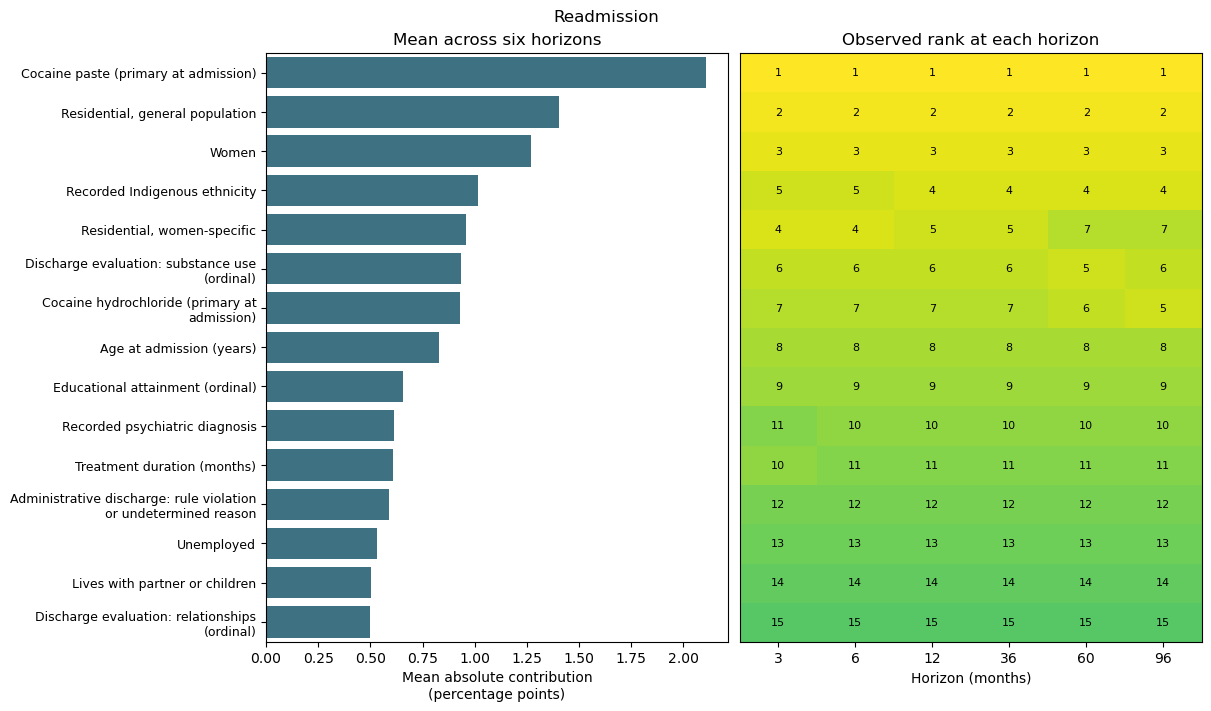

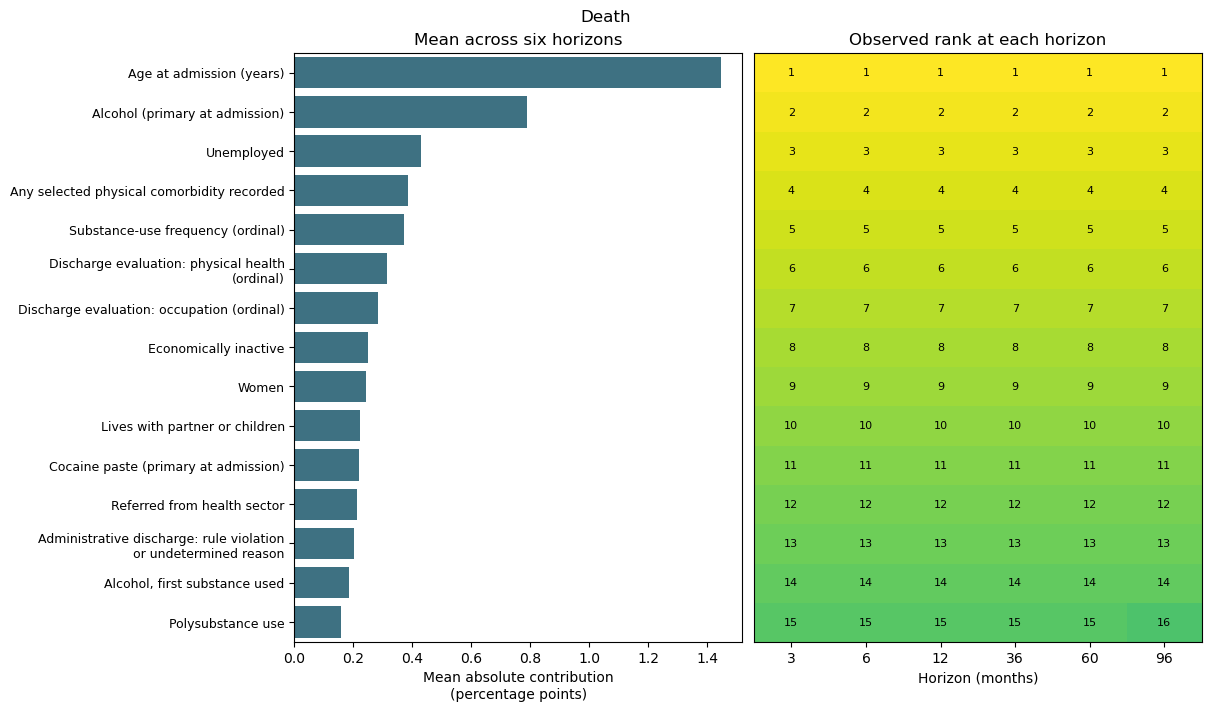

Outcome,Horizon_A,Horizon_B,Rank_Spearman,Top15_overlap,Top15_Jaccard
Readmission,3.0,6.0,0.999784,15,1.000
Readmission,3.0,12.0,0.999639,15,1.000
Readmission,3.0,36.0,0.998846,15,1.000
Readmission,3.0,60.0,0.998268,15,1.000
Readmission,3.0,96.0,0.997763,15,1.000
Readmission,6.0,12.0,0.999856,15,1.000
Readmission,6.0,36.0,0.999278,15,1.000
Readmission,6.0,60.0,0.998701,15,1.000
Readmission,6.0,96.0,0.998268,15,1.000
Readmission,12.0,36.0,0.999423,15,1.000


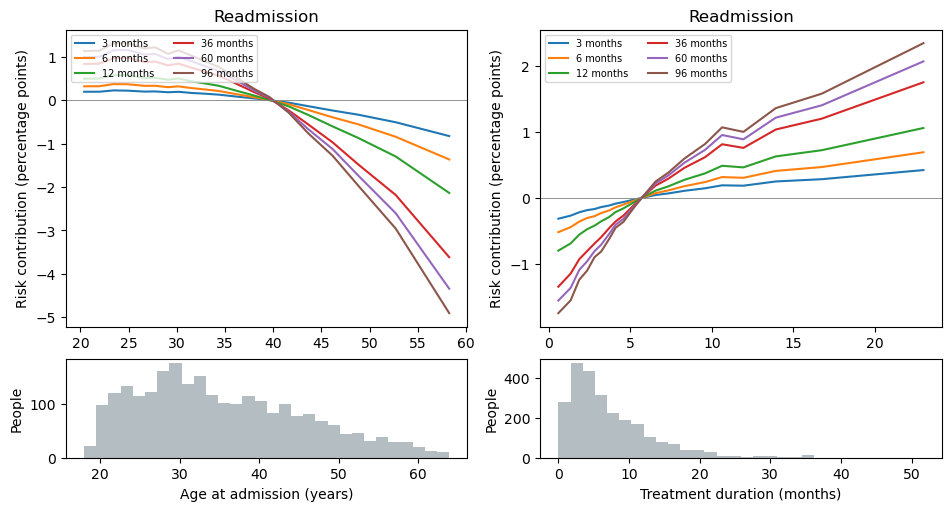

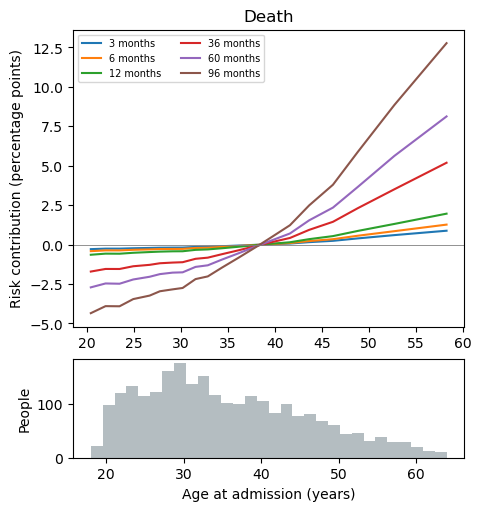

Lines show equal-frequency-bin medians; the histograms reveal sparse tails. A positive contribution raises the model probability relative to the training-background average. These are not causal effects or time-varying coefficients.
The same people, fold networks and Monte Carlo draws are used across horizons. Agreement is descriptive and is not independent temporal validation. First-imputation explanations do not quantify imputation uncertainty.
Elapsed: 0.015 minutes


In [8]:
#| label: ds-shap-explanation-figures
#| message: false
t0 = time.perf_counter()
# Display compact contribution, rank and functional-form summaries without intermediate figure exports.
labels=pd.read_csv(source_path('variable_labels'));display_labels=dict(zip(labels.technical_name,labels.display_label))
for family in ['eva_consumo','eva_sm','eva_fisica','eva_ocupacion','eva_fam','eva_relinterp','eva_transgnorma']:display_labels[family]=family.replace('eva_','Discharge evaluation: ').replace('consumo','substance use').replace('sm','mental health').replace('fisica','physical health').replace('ocupacion','occupation').replace('fam','family').replace('relinterp','relationships').replace('transgnorma','compliance with rules')+' (ordinal)'
display_labels.update({'dit_m':'Treatment duration (months)','porc_pobr':'Municipal poverty index','adm_age_rec3':'Age at admission (years)','ed_attainment_corr':'Educational attainment (ordinal)','prim_sub_freq_rec':'Substance-use frequency (ordinal)'})
import textwrap
consistency=[]
for cause in ['Readmission','Death']:
    fig,axes=plt.subplots(1,2,figsize=(12,7),sharey=True,layout='constrained');fig.suptitle(cause)
    z=selection[selection.outcome==cause].head(15).iloc[::-1];names=[textwrap.fill(display_labels.get(f,f),42) for f in z.feature]
    axes[0].barh(range(len(z)),100*z.mean_abs_shap_risk,color='#3e7182');axes[0].set_yticks(range(len(z)),names,fontsize=9);axes[0].set_xlabel('Mean absolute contribution\n(percentage points)');axes[0].set_title('Mean across six horizons')
    ranks=horizon_ranks[horizon_ranks.outcome==cause].pivot(index='feature',columns='horizon_months',values='rank_h')
    matrix=ranks.loc[z.feature,explanation_horizons].to_numpy()
    axes[1].imshow(matrix,aspect='auto',origin='lower',cmap='viridis_r',vmin=1,vmax=len(features));axes[1].tick_params(axis='y',labelleft=False,left=False);axes[1].set_xticks(range(6),[str(int(h)) for h in explanation_horizons]);axes[1].set_xlabel('Horizon (months)');axes[1].set_title('Observed rank at each horizon')
    for row in range(len(z)):
        for col in range(6):axes[1].text(col,row,str(int(matrix[row,col])),ha='center',va='center',fontsize=8,color='black' if matrix[row,col]<25 else 'white')
    for i,h1 in enumerate(explanation_horizons):
        for h2 in explanation_horizons[i+1:]:
            a=set(ranks.index[ranks[h1]<=15]);b=set(ranks.index[ranks[h2]<=15]);consistency.append({'Outcome':cause,'Horizon_A':h1,'Horizon_B':h2,'Rank_Spearman':float(spearmanr(ranks[h1],ranks[h2]).statistic),'Top15_overlap':len(a&b),'Top15_Jaccard':len(a&b)/len(a|b)})
    plt.show();plt.close(fig)
show_table(pd.DataFrame(consistency),'Descriptive agreement between horizon rankings; dependent summaries, not statistical tests')
for cause in ['Readmission','Death']:
    eligible=selection.loc[(selection.outcome==cause)&selection.qualifies_etable8,'feature'].tolist()
    continuous=[f for f in ['adm_age_rec3','dit_m','porc_pobr'] if f in eligible]
    if not continuous:continue
    fig,axes=plt.subplots(2,len(continuous),figsize=(4.7*len(continuous),5),squeeze=False,layout='constrained',gridspec_kw={'height_ratios':[3,1]})
    for column,feature in enumerate(continuous):
        ax=axes[0,column];j=features.index(feature);x=bundle['X_raw'][feature].to_numpy();bins=pd.qcut(pd.Series(x),q=20,duplicates='drop')
        for k,h in enumerate(explanation_horizons):
            z=pd.DataFrame({'x':x,'s':100*bundle['values'][cause][:,j,k],'bin':bins}).groupby('bin',observed=True).agg(x=('x','median'),s=('s','median'))
            ax.plot(z.x,z.s,label=f'{int(h)} months',lw=1.5)
        ax.axhline(0,color='gray',lw=.6);ax.set_ylabel('Risk contribution (percentage points)');ax.set_title(cause);ax.legend(loc='upper left',fontsize=7,ncol=2)
        axes[1,column].hist(x,bins=30,color='#b4bdc1');axes[1,column].set_ylabel('People');axes[1,column].set_xlabel(display_labels.get(feature,feature))
    plt.show();plt.close(fig)
print('Lines show equal-frequency-bin medians; the histograms reveal sparse tails. A positive contribution raises the model probability relative to the training-background average. These are not causal effects or time-varying coefficients.')
print('The same people, fold networks and Monte Carlo draws are used across horizons. Agreement is descriptive and is not independent temporal validation. First-imputation explanations do not quantify imputation uncertainty.')
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


## Process at a glance {#ds-final-process-flowchart}

```{mermaid}
%%| label: fig-ds-final-process
%%| fig-cap: "DeepSurv sensitivity workflow: from development-only imputation to horizon-specific explanations and Cox comparisons."
flowchart TD
 A["00: split participants first<br/>Five development-only imputations"] --> B["04: train both outcomes<br/>Mortality includes all deaths"]
 B --> C["100 broad trials: top ten checked in all five imputations<br/>50 targeted trials: finalist checked in all five imputations"]
 C --> D["Select by the original C/IBS score<br/>Reuse networks and training baselines"]
 D --> E["05: explain risk at six horizons<br/>Same 2,500 validation participants; imputation 1"]
 E --> F{"Numerical explanation checks pass?"}
 F -->|No| X["Stop before selection<br/>Inspect the explanation error"]
 F -->|Yes| G["Rank at each horizon<br/>Apply descriptive selection rules"]
 G --> H["12: compare Cox sensitivity candidates<br/>Strata, interactions and functional forms"]
 H --> I{"Agreed C/IBS improvement rule met?"}
 I -->|No| J["Keep the current Cox specification"]
 I -->|Yes| K["Flag the candidate for final review"]
 J --> L["13: tables and figures from executed results"]
 K --> L
 classDef stage fill:#edf3f8,stroke:#627d98,color:#172b4d
 classDef decision fill:#fff4d6,stroke:#997a22,color:#172b4d
 classDef halt fill:#fbeaec,stroke:#a63d40,color:#6b1e25
 class A,B,C,D,E,G,H,J,K,L stage
 class F,I decision
 class X halt
 linkStyle default stroke:#52606d,color:#172b4d
```

**How to read this:** the arrows describe the workflow; the saved results and checkpoint below identify what has actually completed. Each explanation targets net risk, **1-S(t)**. Calibration is examined alongside C/IBS in the Cox comparisons. The six explanation horizons are 3, 6, 12, 36, 60 and 96 months. Historical copies of one log-hazard SHAP matrix are retained only as a method control; they do not establish consistency across time.

The holdout and additional cohorts stay outside this discovery branch. Imputation uses the whole development sample before internal CV, as agreed. These sensitivity comparisons do not automatically replace the retained primary models **b/e** or the **Full mortality alternative**.


In [9]:
#| label: ds-shap-handoff-and-session-info
#| message: false
t0 = time.perf_counter()
# Export each horizon explicitly; downstream notebooks reject the old duplicated-matrix contract.
p=object_dir/f'DeepSurv_SHAP_functional_source_{datetime.date.today()}_{shap_signature}.parquet'
functional=[]
for cause in ['Readmission','Death']:
    for k,h in enumerate(explanation_horizons):
        z=pd.concat([bundle['X_raw'].add_prefix('value__'),pd.DataFrame(bundle['values'][cause][:,:,k],columns=['shap__'+f for f in features])],axis=1)
        z['outcome']=cause;z['horizon_months']=h;z['development_row_id']=bundle['ids'];functional.append(z)
pd.concat(functional,ignore_index=True).to_parquet(p,index=False);written.append(p)
handoff={'status':'complete','neural_endpoint':settings['endpoint'],'selection_source':selected_path.relative_to(root).as_posix(),'selection_signature':analysis_signature,'shap_signature':shap_signature,'explanation_method':explanation_settings['method'],'explanation_scale':bundle['shap_scale'],'horizons_months':explanation_horizons.tolist(),'consistency_is_descriptive':True,'rank_percentiles_are_confidence_intervals':False,'predictors':selection_path.relative_to(root).as_posix(),'horizon_ranks':horizon_rank_path.relative_to(root).as_posix(),'interactions':interactions_parquet.relative_to(root).as_posix(),'interaction_horizon_source':interaction_detail_path.relative_to(root).as_posix(),'functional_source':p.relative_to(root).as_posix(),'shap_object':shap_path.relative_to(root).as_posix(),'n_explained':len(bundle['ids']),'imputations_explained':[1],'new_neural_fits':0,'same_log_hazard_SHAP_at_all_horizons':False,'primary_models_changed':False,'nsamples':explanation_settings['nsamples'],'explanation_device':explanation_device,'selection_changes':comparison.loc[comparison.selection_changed,['outcome','feature','historical_selected','new_selected']].to_dict('records')}
hp=object_dir/f'DeepSurv_Cox_handoff_{datetime.date.today()}_{shap_signature}.json';hp.write_text(json.dumps(handoff,indent=2),encoding='utf-8');written.append(hp)
(resolve_path(config['paths']['docs'])/'05_DeepSurv_checkpoint.json').write_text(json.dumps(handoff,indent=2),encoding='utf-8')
show_table(pd.DataFrame([{'Package':name,'Version':importlib.metadata.version(name)} for name in ['numpy','pandas','torch','pycox','shap','optuna','scikit-survival']]),'Session info')
print({'Python':platform.python_version(),'Environment':Path(sys.prefix).name,'Seed':seed,'Threads':threads,'Explanation_device':explanation_device,'Elapsed_minutes':(time.perf_counter()-run_started)/60,'RAM_GiB':psutil.Process().memory_info().rss/2**30})
print(f'Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes')


Package,Version
numpy,2.0.1
pandas,2.3.3
torch,2.5.1
pycox,0.3.0
shap,0.50.0
optuna,4.7.0
scikit-survival,0.27.0


{'Python': '3.11.14', 'Environment': 'surv-deephit', 'Seed': 2125, 'Threads': 1, 'Explanation_device': 'cpu', 'Elapsed_minutes': 2.1855450599997615, 'RAM_GiB': 1.1976966857910156}
Elapsed: 0.005 minutes


In [10]:
#| label: ds-shap-written-files
#| message: false
t0 = time.perf_counter()
# List actual output artifacts with relative paths and sizes.
show_table(pd.DataFrame([{'Relative_path':p.relative_to(root).as_posix(),'Bytes':p.stat().st_size} for p in dict.fromkeys(written)]),'Files in outputs/')
print(json.dumps({'status':'complete','shap_signature':shap_signature,'n_explained':2500,'new_neural_fits':0}))
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Relative_path,Bytes
outputs/objects/DeepSurv_development_contract_2026-10-10_017339fd5962.pkl,5226354
outputs/objects/DeepSurv_horizon_risk_SHAP_fold1_2026-10-10_42af91b0abfa.pkl,1579249
outputs/objects/DeepSurv_horizon_risk_SHAP_fold2_2026-10-10_42af91b0abfa.pkl,1579249
outputs/objects/DeepSurv_horizon_risk_SHAP_fold3_2026-10-10_42af91b0abfa.pkl,1579249
outputs/objects/DeepSurv_horizon_risk_SHAP_fold4_2026-10-10_42af91b0abfa.pkl,1579249
outputs/objects/DeepSurv_horizon_risk_SHAP_fold5_2026-10-10_42af91b0abfa.pkl,1579249
outputs/objects/DeepSurv_horizon_risk_SHAP_2026-10-10_42af91b0abfa.pkl,7867723
outputs/tables/eTable8_DeepSurv_SHAP_source_2026-10-10_42af91b0abfa.csv,17517
outputs/tables/eTable8_DeepSurv_horizon_ranks_2026-10-10_42af91b0abfa.csv,54741
outputs/tables/eTable8_DeepSurv_previous_vs_clean_2026-10-10_42af91b0abfa.csv,25294


{"status": "complete", "shap_signature": "42af91b0abfa", "n_explained": 2500, "new_neural_fits": 0}
Elapsed: 0.000 minutes
